# Exercise 1 (PART 1 + 2): MD simulations of LJ-Ag

Consegna del 24 novembre 2026, risolta punto per punto. Il testo completo, le
note di lettura e lo stato dei sotto-esercizi sono nella pagina
[Consegna e piano](../../book/esame/esercizio1/consegna.md); le note tecniche
(unità, numerica del raccordo, controlli sul codice) sono in
[Note tecniche](../../book/esame/esercizio1/note_tecniche.md).

**Parametri comuni a tutte le simulazioni**

| | |
|---|---|
| Potenziale | Lennard-Jones, $\varepsilon=0.345$ eV, $\sigma=2.644$ Å, $r_c=4.5$ Å |
| Raccordo | polinomio di grado 7 per $r_p<r<r_c$, $r_p=4.2$ Å, coefficienti A…H di `poly7.py` (**sempre**) |
| Termalizzazione | $t_{th}=3$ ps, scartati dalle medie |
| Cella | 256 atomi, `fcc100a256.txt`: un cluster cubico **senza PBC** |
| Criterio sul passo | $\delta E/\lvert\langle E\rangle\rvert<10^{-5}$ ($\delta E$ = deviazione standard di $E_\text{tot}$ dopo $t_{th}$) |

**Il testo, in breve**

1. **Passo ottimale.** Trovare il più grande $\Delta t$ con
   $\delta E/|\langle E\rangle|<10^{-5}$ per $T_\text{ini}=30$, 300, 1200 e
   2500 K, provando $\Delta t$ in $[1,25]$ fs con almeno 8000 passi per prova.
   - Verificare se un passo valido esisterebbe, alle stesse temperature, con
     un **taglio netto**.
   - Visualizzare la traiettoria di un atomo al **centro** del cluster e di
     uno a un **vertice** del cubo, alla temperatura più bassa e più alta, e
     confrontarle.
2. **$\langle T\rangle$ contro $T_\text{ini}$.** Usando i passi ottimali del
   punto 1 e partendo da un minimo trovato con *steepest descent*
   ($C=0.005$, stop a $F_\text{max}<0.001$ eV/Å): run da 50 ps per
   $T_\text{ini}$ in $[30,2500]$ K. Tracciare $\langle T\rangle$ contro
   $T_\text{ini}$, confrontare con i risultati precedenti, verificare quando
   vale $\langle T\rangle=T_\text{ini}/2$ e spiegare perché non vale sempre.

:::{note} Tre note di lettura
- **«Compare with point 2».** Il punto 2 chiede di confrontare «con i
  risultati del punto 2»: è quasi certamente un refuso per **punto 1**, cioè
  i run che partono dal reticolo non minimizzato.
- **Unità di $C$.** Da $\delta\mathbf r=C\,\mathbf F$ si ha
  $[C]=$ Å²/eV, non Å/eV. Il valore resta 0.005.
- **Punto 1 senza minimizzazione.** La *steepest descent* è chiesta «per i
  punti seguenti», quindi nel punto 1 si parte dal reticolo del file.
:::

In [1]:
import sys
from pathlib import Path


def _setup_path():
    root = Path.cwd()
    for _ in range(10):
        if (root / "pyproject.toml").exists():
            break
        root = root.parent
    for sub in ("src", "materials"):
        path = str(root / sub)
        if path not in sys.path:
            sys.path.insert(0, path)
    return root


ROOT = _setup_path()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter, NullFormatter
from poly7 import poly7  # file del corso: materials/poly7.py

from computational_course.fcc_lattice import fcc_supercell
from computational_course.lennard_jones import build_neighbor_list
from computational_course.md import KB_EV, assign_vel, instantaneous_T, kinetic_energy
from computational_course.md_p7 import (
    lj_p7_model,
    production_stats,
    remove_angular_momentum,
    run_nve,
    steepest_descent,
)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True})

EPSILON, SIGMA = 0.345, 2.644  # eV, Å
RC, RP = 4.5, 4.2  # Å
T_TH_PS, SOGLIA = 3.0, 1e-5
NSTEPS = 8000  # «at least 8000 integration steps for each trial»
C_STEEP, F_TOL = 0.005, 1e-3  # Å²/eV, eV/Å
MASS = 108.0 * 1.66e-27 / 16.0  # massa Ag in unità di codice (eV s²/Å²)
FS, A_AG, SEED = 1e-15, 4.1604, 33282739

lp = poly7(EPSILON, SIGMA, RC, RP)
P7 = np.array([lp.A, lp.B, lp.C, lp.D, lp.E, lp.F, lp.G, lp.H])  # termini r^0 ... r^7
polyval, polyder = np.polynomial.polynomial.polyval, np.polynomial.polynomial.polyder
dP7 = polyder(P7)

FILE_256 = ROOT / "data" / "raw" / "fcc100a256.txt"
if FILE_256.exists():
    pos0, origine = np.loadtxt(FILE_256), "fcc100a256.txt"
else:
    pos0, origine = fcc_supercell(A_AG, 4, 4, 4)[0], "ricostruita (4x4x4 celle, a = 4.1604 Å)"
natoms = len(pos0)
print(f"cella: {origine}, N = {natoms}")

T_P1 = [30.0, 300.0, 1200.0, 2500.0]
COLORI = dict(zip(T_P1, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
GRIGIO = "#52514e"

cella: ricostruita (4x4x4 celle, a = 4.1604 Å), N = 256


## 0. Il modello e il codice

$$
\phi(r)=\begin{cases}
4\varepsilon\left[(\sigma/r)^{12}-(\sigma/r)^6\right] & r\le r_p\\
P_7(r)=A+Br+\dots+Hr^7 & r_p<r<r_c\\
0 & r\ge r_c
\end{cases}
\qquad
\mathbf F(k)=\sum_{j}f(r_{kj})\,\frac{\mathbf r_k-\mathbf r_j}{r_{kj}},\quad f=-\frac{\mathrm d\phi}{\mathrm dr}
$$

- **Raccordo:** il $P_7$ rende $\phi$, $\phi'$, $\phi''$ e $\phi'''$
  continue in $r_p$ e le porta a zero in $r_c$.
- **Taglio netto** (solo come controllo nel punto 1): $\phi_{LJ}$ fino a
  $r_c$, con un salto di $|\phi_{LJ}(r_c)|=0.054$ eV.
- **Codice:** `calcNbrs`, `calcEnergy` e `calcForces` sono scritte qui in
  chiaro. Le MD lunghe usano la stessa fisica compilata con Numba
  (`computational_course.md_p7`); la cella controlla che le due versioni
  coincidano.
- **Integratore:** *velocity Verlet* in NVE.
- **Velocità iniziali:** distribuzione uniforme con quantità di moto **e
  momento angolare** nulli, poi riscalate esattamente a $T_\text{ini}$. Il
  cluster è isolato e il momento angolare si conserva: senza toglierlo, il
  cluster ruoterebbe rigidamente e la traiettoria dei vertici ne sarebbe
  dominata.

In [2]:
def calcNbrs(pos):
    # liste dei vicini entro r_c (cluster: nessuna PBC)
    return build_neighbor_list(pos, RC)


def _coppie(pos, nNbrs, whichNbrs, raccordo):
    # per ogni coppia (i, j) della lista: r_ij, φ(r) e f(r) = -dφ/dr
    piena = np.arange(whichNbrs.shape[1])[None, :] < nNbrs[:, None]
    i, j = np.nonzero(piena)[0], whichNbrs[piena]
    rij = pos[i] - pos[j]
    r = np.sqrt(rij[:, 0] ** 2 + rij[:, 1] ** 2 + rij[:, 2] ** 2)
    sr6 = (SIGMA / r) ** 6
    phi = 4 * EPSILON * (sr6**2 - sr6)
    f = 24 * EPSILON * (2 * sr6**2 - sr6) / r
    if raccordo:
        coda = r > RP
        phi[coda] = polyval(r[coda], P7)  # P7(r)
        f[coda] = -polyval(r[coda], dP7)  # -P7'(r)
    return i, rij, r, phi, f


def calcEnergy(pos, nNbrs, whichNbrs, raccordo=True):
    _, _, _, phi, _ = _coppie(pos, nNbrs, whichNbrs, raccordo)
    return 0.5 * phi.sum()  # ogni coppia compare due volte nella lista


def calcForces(pos, nNbrs, whichNbrs, raccordo=True):
    i, rij, r, _, f = _coppie(pos, nNbrs, whichNbrs, raccordo)
    forces = np.zeros_like(pos)
    np.add.at(forces, i, (f / r)[:, None] * rij)  # F(i) += f(r_ij) (r_i - r_j)/r_ij
    return forces


raccordo = lj_p7_model(SIGMA, EPSILON, RC, rp=RP, p7=P7)  # versione compilata, con P7
netto = lj_p7_model(SIGMA, EPSILON, RC)  # versione compilata, taglio netto

prova_pos = pos0 + 0.1 * np.random.default_rng(1).standard_normal(pos0.shape)
nN, wN = calcNbrs(prova_pos)
for nome, modello, flag in (("P7", raccordo, True), ("netto", netto, False)):
    e_c, f_c, _ = modello(prova_pos)
    print(f"{nome:5s}: |ΔE| = {abs(calcEnergy(prova_pos, nN, wN, flag) - e_c):.0e} eV, "
          f"max|ΔF| = {np.abs(calcForces(prova_pos, nN, wN, flag) - f_c).max():.0e} eV/Å "
          "(calcForces contro la versione compilata)")

display(pd.DataFrame(
    {"P7^(k)(r_p)": [polyval(RP, polyder(P7, k)) for k in range(4)],
     "φ_LJ^(k)(r_p)": 4 * EPSILON * np.array([
         SIGMA**12 / RP**12 - SIGMA**6 / RP**6,
         -12 * SIGMA**12 / RP**13 + 6 * SIGMA**6 / RP**7,
         156 * SIGMA**12 / RP**14 - 42 * SIGMA**6 / RP**8,
         -2184 * SIGMA**12 / RP**15 + 336 * SIGMA**6 / RP**9]),
     "P7^(k)(r_c)": [polyval(RC, polyder(P7, k)) for k in range(4)]},
    index=pd.Index(range(4), name="derivata k"),
).style.format("{:.3e}").set_caption("Raccordo P7: continuità in r_p e zero in r_c"))


def velocita(pos, t_ini, seed=SEED):
    # P = 0 (assign_vel), L = 0, poi riscalate esattamente a T_ini
    vel = remove_angular_momentum(pos, assign_vel(natoms, MASS, t_ini, seed=seed), MASS)
    return vel * np.sqrt(t_ini / instantaneous_T(kinetic_energy(vel, MASS), natoms))


def prova(modello, pos, t_ini, dt_fs, nsteps, seed=SEED, sample_every=0):
    # una MD NVE; medie dopo t_th
    res = run_nve(pos, velocita(pos, t_ini, seed), MASS, dt_fs * FS, nsteps, modello,
                  sample_every=sample_every)
    return {"dt": dt_fs, **production_stats(res, int(round(T_TH_PS * 1000 / dt_fs))),
            "n_cross": res["n_cross"], "stabile": res["stable"], "res": res}

P7   : |ΔE| = 3e-13 eV, max|ΔF| = 1e-14 eV/Å (calcForces contro la versione compilata)
netto: |ΔE| = 3e-13 eV, max|ΔF| = 1e-14 eV/Å (calcForces contro la versione compilata)


,P7^(k)(r_p),φ_LJ^(k)(r_p),P7^(k)(r_c)
derivata k,,,
0,-8.055e-02,-8.055e-02,-5.662e-06
1,1.074e-01,1.074e-01,-5.186e-06
2,-1.572e-01,-1.572e-01,-3.278e-06
3,2.319e-01,2.319e-01,-1.669e-06


Le due versioni di energia e forze coincidono (differenza $10^{-13}$ eV). Il
raccordo rispetta le condizioni fino a qualche $10^{-6}$: è un limite
numerico, perché i coefficienti arrivano a $10^8$ con segni alterni e nella
somma si perdono cifre. Il residuo è comunque 10 000 volte più piccolo del
salto del taglio netto.

## 1. Punto 1 — passo temporale ottimale

**Come.** Per ogni $T_\text{ini}$ e ogni $\Delta t$ in $[1,25]$ fs si fa una
MD da **8000 passi** partendo dal reticolo del file, sempre con le stesse
velocità iniziali. Si calcola $\delta E/|\langle E\rangle|$ dopo $t_{th}$, e si
contano le coppie che **attraversano $r_c$**.

- La durata cambia con $\Delta t$: 8 ps a 1 fs (5 ps di statistica dopo
  $t_{th}$), 200 ps a 25 fs.
- Lo stesso protocollo si ripete con il taglio netto.
- **Passi validi** = punti sotto la linea della soglia; **passo ottimale** =
  il più grande tra i validi.

,P7: Δt validi,P7: Δt ottimale,P7: δE/|⟨E⟩| all'ottimale,netto: Δt validi,netto: δE/|⟨E⟩| a 1 fs,"attraversamenti di r_c (1 fs, 8 ps)"
T_ini [K],,,,,,
30,1–20 fs,20 fs,6.1e-06,1–25 fs,1.5e-08,0
300,1–8 fs,8 fs,8.9e-06,nessuno,6.7e-05,46
1200,1–3 fs,3 fs,5.7e-06,nessuno,8.4e-04,4939
2500,1–2 fs,2 fs,4.8e-06,nessuno,2.2e-03,14465


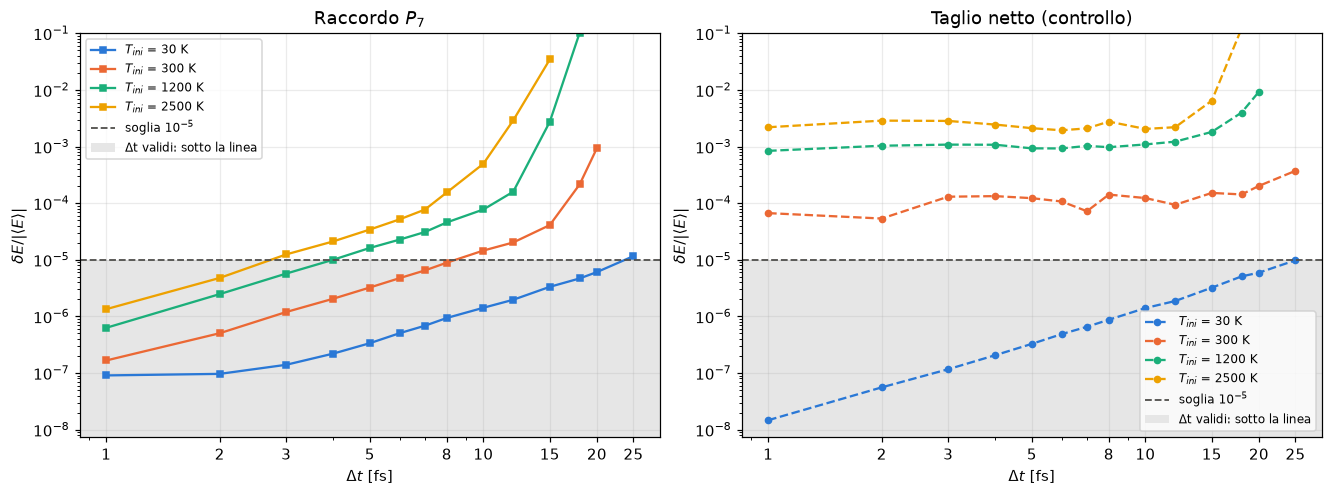

In [3]:
DTS_FS = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 18, 20, 25]


def validi(prove):
    return [p["dt"] for p in prove if p["dE_rel"] < SOGLIA]


def testo_validi(prove):
    ok = validi(prove)
    return f"{ok[0]:g}–{ok[-1]:g} fs" if len(ok) > 1 else (f"{ok[0]:g} fs" if ok else "nessuno")


def ottimale(prove):
    ok = validi(prove)
    return max(ok) if ok else np.nan


scan = {
    nome: {t: [prova(modello, pos0, t, dt, NSTEPS) for dt in DTS_FS] for t in T_P1}
    for nome, modello in (("P7", raccordo), ("netto", netto))
}
DT_OTT = {t: ottimale(scan["P7"][t]) for t in T_P1}

righe = []
for t in T_P1:
    p7, nt = scan["P7"][t], scan["netto"][t]
    i_ott = DTS_FS.index(DT_OTT[t])
    righe.append({
        "T_ini [K]": f"{t:g}",
        "P7: Δt validi": testo_validi(p7),
        "P7: Δt ottimale": f"{DT_OTT[t]:g} fs",
        "P7: δE/|⟨E⟩| all'ottimale": f"{p7[i_ott]['dE_rel']:.1e}",
        "netto: Δt validi": testo_validi(nt),
        "netto: δE/|⟨E⟩| a 1 fs": f"{nt[0]['dE_rel']:.1e}",
        "attraversamenti di r_c (1 fs, 8 ps)": nt[0]["n_cross"],
    })
display(pd.DataFrame(righe).set_index("T_ini [K]").style.set_caption(
    "Punto 1 — passo ottimale con il raccordo P7 e controllo con il taglio netto"))


tutti_dE = [p["dE_rel"] for m in scan.values() for prove in m.values() for p in prove]
Y_LIM = (0.5 * np.nanmin(tutti_dE), 0.1)


def assi_dt(ax, titolo):
    ax.set(xscale="log", yscale="log", xlabel=r"$\Delta t$ [fs]", ylim=Y_LIM,
           ylabel=r"$\delta E/|\langle E\rangle|$", title=titolo)
    ax.axhline(SOGLIA, color=GRIGIO, ls="--", lw=1.2, label="soglia $10^{-5}$")
    ax.axhspan(Y_LIM[0], SOGLIA, color="0.9", lw=0, zorder=0, label="Δt validi: sotto la linea")
    ax.set_xticks([1, 2, 3, 5, 8, 10, 15, 20, 25])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.legend(fontsize=8)


fig, (ax_p7, ax_nt) = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for ax, nome, stile in ((ax_p7, "P7", "s-"), (ax_nt, "netto", "o--")):
    for t in T_P1:
        ax.plot(DTS_FS, [p["dE_rel"] for p in scan[nome][t]], stile, color=COLORI[t], ms=4, lw=1.5,
                label=f"$T_{{ini}}$ = {t:g} K")
assi_dt(ax_p7, "Raccordo $P_7$")
assi_dt(ax_nt, "Taglio netto (controllo)")
plt.show()

**Risultato.**

- **Con il $P_7$ il passo ottimale è 20 fs a 30 K, 8 fs a 300 K, 3 fs a
  1200 K e 2 fs a 2500 K.** Più la temperatura è alta, più gli atomi sono
  veloci, e più il passo va accorciato.
- Finché la simulazione è stabile l'errore cresce come $\Delta t^2$: in scala
  log-log le curve sono rette quasi parallele. Con passi grandi e $T$ alta la
  simulazione diverge, e le curve escono dal grafico.
- **Con il taglio netto un passo valido esiste solo a 30 K** (tutti fino a
  25 fs, l'ultimo al limite della soglia). Già a 300 K nessun passo è valido:
  $\delta E/|\langle E\rangle|\approx7\times10^{-5}$ a 1 fs, e le curve sono
  **piatte**, cioè ridurre $\Delta t$ non aiuta.

**Perché.** Con il taglio netto, ogni volta che una coppia attraversa $r_c$
l'energia salta di $0.054$ eV. Gli attraversamenti dipendono dalla
temperatura, non dal passo: nessuno a 30 K, 46 in 8 ps a 300 K, circa 14 500
a 2500 K (ultima colonna). È un errore del **modello**, non dell'integratore.
Con il $P_7$ energia e forza sono già nulle in $r_c$, e attraversarlo non
costa nulla.

(A 30 K, con 1–2 fs, il $P_7$ si ferma a circa $10^{-7}$ invece di scendere
come il taglio netto. Lo causa un piccolo scalino ($4\times10^{-6}$ eV) dei
coefficienti in $r_p$, è 100 volte sotto la soglia ed è analizzato nel
[notebook dei punti 1–2](../archivio/punti_1_2_passo_temporale.ipynb), §3.1.)

### Controlli sul passo ottimale

Due verifiche, perché il passo ottimale viene da una singola traiettoria e da
un criterio che misura solo le fluttuazioni:

1. **Robustezza.** $\delta E/|\langle E\rangle|$ cambia di qualche punto
   percentuale con il seme delle velocità. Per ogni temperatura si ripetono il
   passo ottimale e il successivo con 4 semi.
2. **Che cosa non vede il criterio.** $\delta E$ è la deviazione standard di
   $E_\text{tot}$ attorno alla sua media. Se la media stessa si sposta rispetto
   all'energia iniziale $E_0$, il criterio non se ne accorge. A 30 K si
   confrontano il passo ottimale (20 fs) e 2 fs.

In [4]:
SEMI4 = (SEED, 20260101, 555000111, 987654321)
righe = []
for t in T_P1:
    i = DTS_FS.index(DT_OTT[t])
    for dt in DTS_FS[i:i + 2]:
        de = np.array([prova(raccordo, pos0, t, dt, NSTEPS, seed=s)["dE_rel"] for s in SEMI4])
        righe.append({"T_ini [K]": f"{t:g}", "Δt [fs]": f"{dt:g}" + (" (ottimale)" if dt == DT_OTT[t] else ""),
                      "δE/|⟨E⟩| min": f"{np.nanmin(de):.1e}", "δE/|⟨E⟩| max": f"{np.nanmax(de):.1e}",
                      "valido con": f"{np.count_nonzero(de < SOGLIA)} semi su 4"})
display(pd.DataFrame(righe).set_index(["T_ini [K]", "Δt [fs]"]).style.set_caption(
    "Robustezza del passo ottimale: 4 semi delle velocità iniziali (8000 passi)"))

for dt in (DT_OTT[30.0], 2):
    p = prova(raccordo, pos0, 30.0, dt, NSTEPS)
    res = p["res"]
    k0, e0 = kinetic_energy(velocita(pos0, 30.0), MASS), raccordo(pos0)[0]
    ith = int(round(T_TH_PS * 1000 / dt))
    print(f"30 K, Δt = {dt:2g} fs: (⟨E⟩ - E0)/K0 = {(np.mean(res['etot'][ith:]) - e0 - k0) / k0:+.3f}, "
          f"δE/|⟨E⟩| = {p['dE_rel']:.1e}, ⟨T⟩ = {p['T_mean']:.2f} K")

30 K, Δt = 20 fs: (⟨E⟩ - E0)/K0 = +0.042, δE/|⟨E⟩| = 6.1e-06, ⟨T⟩ = 18.16 K


30 K, Δt =  2 fs: (⟨E⟩ - E0)/K0 = +0.000, δE/|⟨E⟩| = 9.6e-08, ⟨T⟩ = 18.40 K


**Risultato.**

- **I passi ottimali sono robusti.** Tutti e quattro restano validi con 4 semi
  su 4, mentre il passo successivo fallisce con la maggior parte dei semi. A
  1200 K il passo di 4 fs passa con 2 semi su 4: è al limite, e 3 fs è la
  scelta sicura.
- **Il criterio non vede lo spostamento della media.** A 30 K con 20 fs
  $\delta E/|\langle E\rangle|=6\times10^{-6}$ rispetta il criterio, ma la
  media di $E_\text{tot}$ è più alta di $E_0$ del 4% di $K_0$. È l'energia
  «ombra» di *velocity Verlet*: l'integratore conserva esattamente una
  quantità vicina all'energia, e la differenza cresce con
  $(\omega\Delta t)^2$. Per il modo più veloce (periodo 131 fs) a 20 fs,
  $\omega\Delta t\approx1$. Con 2 fs lo spostamento sparisce.
- **L'effetto su $\langle T\rangle$ è piccolo:** 18.16 K contro 18.40 K
  ($-1.3\%$), molto meno degli effetti discussi nel punto 2 (+21% a 30 K per
  la partenza fuori dal minimo).

### Traiettorie: un atomo al centro e uno a un vertice

Si ripetono i run al passo ottimale a 30 K e a 2500 K, salvando le posizioni
a ogni passo. Gli atomi scelti sono:

- **centro:** l'atomo più vicino al centro del cluster;
- **vertice:** uno dei vertici occupati del cubo (atomo con 3 primi vicini).
  Con questa costruzione ne sono occupati solo 4 su 8.

Ogni pannello mostra lo spostamento dalla posizione iniziale, proiettato sul
piano $x$–$y$, con la stessa scala per i due atomi alla stessa temperatura.

atomo al centro: 89 (12 primi vicini); atomo al vertice: 0 (3 primi vicini)


senza togliere L: a 2500 K il vertice (a 12.6 Å dal centro) si sposterebbe di 7.3 Å in 16 ps per la sola rotazione


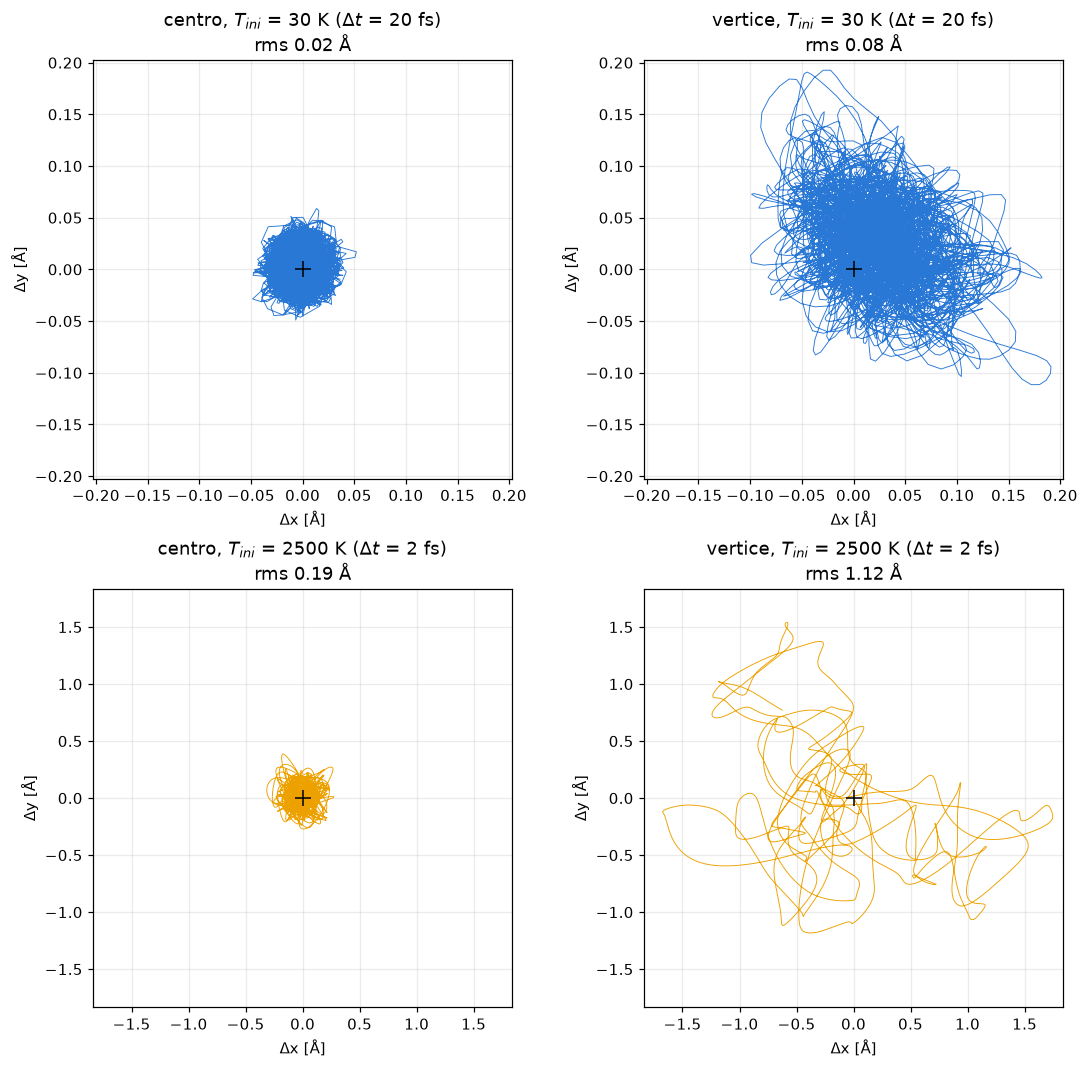

,rms attorno alla posizione media [Å],distanza massima dal sito iniziale [Å],distanza finale [Å]
"30 K, centro",0.025,0.07,0.02
"30 K, vertice",0.075,0.22,0.05
"2500 K, centro",0.190,0.48,0.13
"2500 K, vertice",1.115,2.57,1.10


In [5]:
d0 = np.linalg.norm(pos0[:, None] - pos0[None], axis=-1)
coord = np.count_nonzero((d0 > 0.1) & (d0 < 0.5 * (A_AG / np.sqrt(2) + A_AG)), axis=1)
ATOMI = {"centro": int(np.argmin(np.linalg.norm(pos0 - pos0.mean(axis=0), axis=1))),
         "vertice": int(np.where(coord == 3)[0][0])}
print(f"atomo al centro: {ATOMI['centro']} ({coord[ATOMI['centro']]} primi vicini); "
      f"atomo al vertice: {ATOMI['vertice']} ({coord[ATOMI['vertice']]} primi vicini)")

traiettorie = {t: prova(raccordo, pos0, t, DT_OTT[t], NSTEPS, sample_every=1) for t in (30.0, 2500.0)}

# senza togliere il momento angolare, quanto sposterebbe il vertice la sola rotazione rigida?
rel = pos0 - pos0.mean(axis=0)
inerzia = MASS * (np.einsum("ij,ij->", rel, rel) * np.eye(3) - rel.T @ rel)
omega = np.linalg.solve(inerzia, MASS * np.cross(rel, assign_vel(natoms, MASS, 2500.0, seed=SEED)).sum(axis=0))
durata = NSTEPS * DT_OTT[2500.0] * FS
print(f"senza togliere L: a 2500 K il vertice (a {np.linalg.norm(rel[ATOMI['vertice']]):.1f} Å dal centro) "
      f"si sposterebbe di {np.linalg.norm(omega) * durata * np.linalg.norm(rel[ATOMI['vertice']]):.1f} Å "
      f"in {durata * 1e12:.0f} ps per la sola rotazione")

fig, assi = plt.subplots(2, 2, figsize=(10, 9.6), constrained_layout=True)
tab_traj = {}
for riga, t in zip(assi, (30.0, 2500.0)):
    frames = traiettorie[t]["res"]["frames"]
    estremo = 1.05 * max(np.abs(frames[:, k, :2] - pos0[k, :2]).max() for k in ATOMI.values())
    for ax, (nome, k) in zip(riga, ATOMI.items()):
        d = frames[:, k] - pos0[k]
        ax.plot(d[:, 0], d[:, 1], lw=0.6, color=COLORI[t])
        ax.plot(0, 0, "+", color="black", ms=10)
        dist = np.linalg.norm(d, axis=1)
        prod = frames[int(round(T_TH_PS * 1000 / DT_OTT[t])):, k]
        rms = np.sqrt(((prod - prod.mean(axis=0)) ** 2).sum(axis=1).mean())
        tab_traj[f"{t:g} K, {nome}"] = {"rms attorno alla posizione media [Å]": f"{rms:.3f}",
                                        "distanza massima dal sito iniziale [Å]": f"{dist.max():.2f}",
                                        "distanza finale [Å]": f"{dist[-1]:.2f}"}
        ax.set(xlim=(-estremo, estremo), ylim=(-estremo, estremo), aspect="equal",
               xlabel="Δx [Å]", ylabel="Δy [Å]",
               title=f"{nome}, $T_{{ini}}$ = {t:g} K ($\\Delta t$ = {DT_OTT[t]:g} fs)\nrms {rms:.2f} Å")
plt.show()
display(pd.DataFrame(tab_traj).T.style.set_caption(
    f"Traiettorie dei due atomi ({NSTEPS} passi al passo ottimale; rms calcolato dopo t_th)"))

**Confronto tra le traiettorie.**

- **30 K.** Entrambi gli atomi oscillano attorno al proprio sito. Il vertice
  oscilla circa **3 volte** più del centro: ha solo 3 primi vicini invece di
  12, quindi è trattenuto da meno legami e il potenziale attorno a lui è più
  morbido. La sua nuvola è anche spostata di qualche centesimo di Å verso
  $+x,+y$, cioè verso l'interno del cluster. Il reticolo di partenza non è un
  minimo (nel punto 1 non si minimizza), e il vertice si rilassa verso
  l'interno mentre oscilla (vedi il §2).
- **2500 K** ($\langle T\rangle\approx1080$ K). Il **centro** vibra ancora
  attorno al sito: rms $0.19$ Å, al massimo $0.5$ Å, molto meno della distanza
  tra primi vicini ($2.94$ Å). L'interno resta un solido. Il **vertice**
  invece si allontana fino a circa $2.6$ Å, quasi un passo reticolare, e vaga
  sulla superficie senza una posizione fissa: il suo rms è 6 volte quello del
  centro.
- Gli atomi di superficie, meno legati, diventano mobili molto prima di
  quelli interni. Questo conterà anche nel punto 2.
- **Perché si toglie il momento angolare.** Senza toglierlo, a 2500 K il
  vertice si sposterebbe di circa 7 Å in 16 ps per la sola rotazione rigida
  del cluster (riga stampata sopra la figura): più del suo moto vero, che
  verrebbe nascosto.

## 2. *Steepest descent*: il punto di partenza per il punto 2

**Come.** Lo pseudocodice della slide 38, con le **stesse** `calcNbrs` e
`calcForces` del §0: $\mathbf r(k)\leftarrow\mathbf r(k)+C\,\mathbf F(k)$
con $C=0.005$ Å²/eV, fino a $\max_k|\mathbf F(k)|<10^{-3}$ eV/Å. La teoria è
nel [capitolo dedicato](../../book/teoria/06_steepest_descent.md).

convergenza in 598 iterazioni: E -453.4502 -> -453.6714 eV (ΔE = -0.2212 eV); F_max 0.197 -> 1.0e-03 eV/Å
energia sempre decrescente: True; spostamento massimo 0.050 Å (atomo con 3 primi vicini), medio 0.020 Å


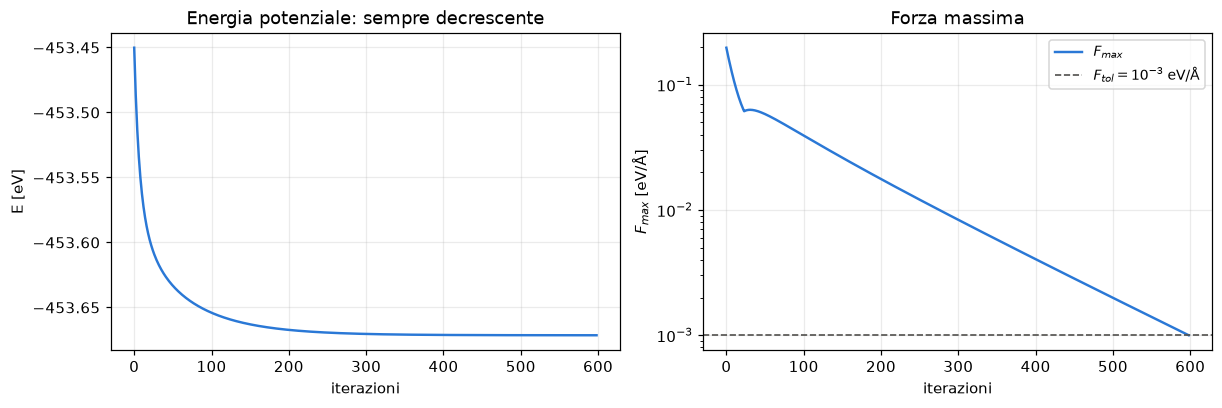

In [6]:
Csteep, ftoll, maxStep = C_STEEP, F_TOL, 10_000
pos = pos0.copy()
energia, forza_max = [], []
for iStep in range(maxStep):
    nNbrs, whichNbrs = calcNbrs(pos)  # liste dei vicini
    forces = calcForces(pos, nNbrs, whichNbrs)  # la stessa funzione della MD
    maxf = np.max(np.sqrt(forces[:, 0] ** 2 + forces[:, 1] ** 2 + forces[:, 2] ** 2))
    energia.append(calcEnergy(pos, nNbrs, whichNbrs))
    forza_max.append(maxf)
    if maxf < ftoll:
        break  # convergenza
    pos = pos + Csteep * forces
pos_min, e_min = pos, energia[-1]
spost = np.linalg.norm(pos_min - pos0, axis=1)
print(f"convergenza in {iStep} iterazioni: E {energia[0]:.4f} -> {e_min:.4f} eV "
      f"(ΔE = {e_min - energia[0]:.4f} eV); F_max {forza_max[0]:.3f} -> {maxf:.1e} eV/Å")
print(f"energia sempre decrescente: {bool(np.all(np.diff(energia) <= 0))}; "
      f"spostamento massimo {spost.max():.3f} Å (atomo con {coord[np.argmax(spost)]} primi vicini), "
      f"medio {spost.mean():.3f} Å")

fig, (ax_e, ax_f) = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
ax_e.plot(energia, color=COLORI[30.0], lw=1.6)
ax_e.set(xlabel="iterazioni", ylabel="E [eV]", title="Energia potenziale: sempre decrescente")
ax_f.semilogy(forza_max, color=COLORI[30.0], lw=1.6, label="$F_{max}$")
ax_f.axhline(F_TOL, color=GRIGIO, ls="--", lw=1.1, label=r"$F_{tol}=10^{-3}$ eV/Å")
ax_f.set(xlabel="iterazioni", ylabel=r"$F_{max}$ [eV/Å]", title="Forza massima")
ax_f.legend(fontsize=9)
plt.show()

**Risultato.**

- La discesa converge in 598 iterazioni. L'energia scende **a ogni passo** e
  guadagna $0.22$ eV in tutto, meno di 1 meV per atomo.
- $F_\text{max}$ cala quasi in modo esponenziale (retta in scala log), con un
  piccolo rialzo iniziale. È ammesso: si minimizza l'energia, non la forza
  del singolo atomo.
- Lo spostamento più grande è $0.05$ Å, ai vertici, verso l'interno: il
  cluster si contrae di poco.

## 3. Punto 2 — $\langle T\rangle$ in funzione di $T_\text{ini}$

**Come.**

- 12 valori di $T_\text{ini}$ tra 30 e 2500 K, run da **50 ps** dal minimo
  del §2, raccordo $P_7$, 3 semi delle velocità per ogni temperatura.
- **Passo:** il testo chiede quelli del punto 1, trovati a 30, 300, 1200 e
  2500 K. A una temperatura intermedia si usa il passo della prima
  temperatura del punto 1 **non inferiore** (ad esempio 700 K → passo di
  1200 K). È la scelta prudente, perché il passo valido scende con $T$.
- **Confronto con il punto 1:** si mettono sullo stesso grafico i
  $\langle T\rangle$ dei run al passo ottimale del punto 1, che partono dal
  reticolo **non** minimizzato.

,Δt [fs],passi,⟨T⟩ [K],⟨T⟩/(T_ini/2),δE/|⟨E⟩| max,rms interni [Å],rms superficie [Å],atomi fuori sito,E minimo finale − E cubo [eV]
T_ini [K],,,,,,,,,
30,20,2500,15.0 ± 0.0,1.002,5.5e-06,0.02,0.04,0,+0.00
100,8,6250,50.8 ± 0.0,1.016,2.5e-06,0.04,0.06,0,+0.00
200,8,6250,102.6 ± 0.0,1.026,5.5e-06,0.06,0.08,0,+0.00
300,8,6250,154.7 ± 0.0,1.032,8.5e-06,0.07,0.10,0,+0.00
500,3,16667,258.3 ± 0.0,1.033,2.1e-06,0.09,0.12,0,+0.00
700,3,16667,358.5 ± 0.2,1.024,3.1e-06,0.10,0.15,0,+0.00
900,3,16667,454.0 ± 0.8,1.009,4.0e-06,0.12,0.18,1,+0.16
1200,3,16667,588.5 ± 1.7,0.981,5.5e-06,0.13,0.22,2,+0.38
1500,2,25000,717.7 ± 0.4,0.957,3.1e-06,0.15,0.28,3,+0.21


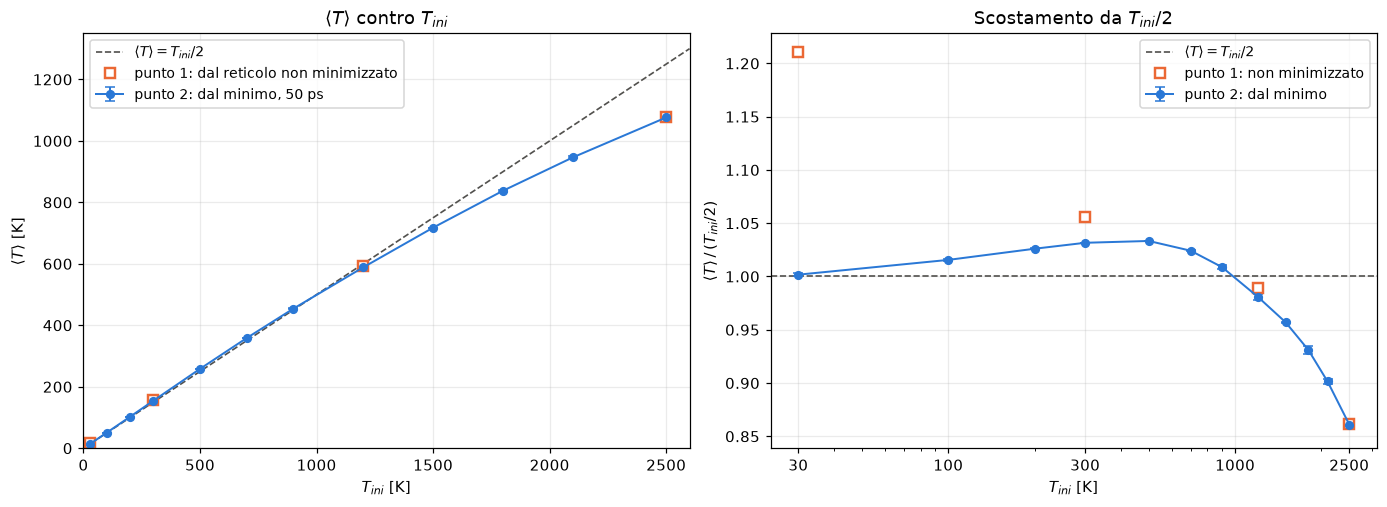

In [7]:
T_P2 = [30.0, 100.0, 200.0, 300.0, 500.0, 700.0, 900.0, 1200.0, 1500.0, 1800.0, 2100.0, 2500.0]
SEMI = (SEED, 20260101, 555000111)


def passo_per(t_ini):
    return DT_OTT[min(t for t in T_P1 if t >= t_ini)]


interni = coord == 12
punto2 = {}
for t in T_P2:
    dt = passo_per(t)
    nsteps = int(round(50_000 / dt))
    runs = []
    for seed in SEMI:
        p = prova(raccordo, pos_min, t, dt, nsteps, seed=seed, sample_every=max(1, int(round(25 / dt))))
        frames = p["res"]["frames"]
        prod = frames[frames.shape[0] * 3 // 50:]  # dopo t_th = 3 ps su 50 ps
        rms = np.sqrt(((prod - prod.mean(axis=0)) ** 2).sum(axis=-1).mean(axis=0))
        p["rms_interni"], p["rms_superficie"] = rms[interni].mean(), rms[~interni].mean()
        p["fuori_sito"] = int(np.count_nonzero(np.linalg.norm(p["res"]["pos"] - pos_min, axis=1) > A_AG / np.sqrt(8)))
        # in quale minimo è finito il sistema? si minimizza la configurazione finale
        quench = steepest_descent(p["res"]["pos"], raccordo, c=C_STEEP, ftol=F_TOL, max_iter=20_000)
        p["dE_quench"] = quench["energy"][-1] - e_min
        p.pop("res")  # libera la memoria: servono solo le medie
        runs.append(p)
    punto2[t] = {"dt": dt, "nsteps": nsteps, "runs": runs}

t_med = np.array([np.mean([p["T_mean"] for p in punto2[t]["runs"]]) for t in T_P2])
t_std = np.array([np.std([p["T_mean"] for p in punto2[t]["runs"]]) for t in T_P2])
t_p1 = np.array([scan["P7"][t][DTS_FS.index(DT_OTT[t])]["T_mean"] for t in T_P1])

display(pd.DataFrame(
    [{"T_ini [K]": f"{t:g}", "Δt [fs]": f"{punto2[t]['dt']:g}", "passi": punto2[t]["nsteps"],
      "⟨T⟩ [K]": f"{m:.1f} ± {s:.1f}", "⟨T⟩/(T_ini/2)": f"{m / (t / 2):.3f}",
      "δE/|⟨E⟩| max": f"{max(p['dE_rel'] for p in punto2[t]['runs']):.1e}",
      "rms interni [Å]": f"{np.mean([p['rms_interni'] for p in punto2[t]['runs']]):.2f}",
      "rms superficie [Å]": f"{np.mean([p['rms_superficie'] for p in punto2[t]['runs']]):.2f}",
      "atomi fuori sito": f"{np.mean([p['fuori_sito'] for p in punto2[t]['runs']]):.0f}",
      "E minimo finale − E cubo [eV]": f"{np.mean([p['dE_quench'] for p in punto2[t]['runs']]):+.2f}"}
     for t, m, s in zip(T_P2, t_med, t_std)]
).set_index("T_ini [K]").style.set_caption(
    "Punto 2 — 50 ps dal minimo (media ± dev. std. su 3 semi). rms: ampiezza media delle "
    "oscillazioni attorno alla posizione media; fuori sito: spostati di oltre metà della "
    "distanza tra primi vicini a fine run; E minimo finale: energia della configurazione finale "
    "minimizzata, rispetto al minimo di partenza (il cubo)"))

fig, (ax_t, ax_r) = plt.subplots(1, 2, figsize=(12.5, 4.5), constrained_layout=True)
ax_t.plot([0, 2600], [0, 1300], "--", color=GRIGIO, lw=1.1, label=r"$\langle T\rangle = T_{ini}/2$")
ax_t.errorbar(T_P2, t_med, yerr=t_std, fmt="o-", color="#2a78d6", ms=5, lw=1.3, capsize=3,
              label="punto 2: dal minimo, 50 ps")
ax_t.plot(T_P1, t_p1, "s", color="#eb6834", ms=7, mfc="white", mew=1.6,
          label="punto 1: dal reticolo non minimizzato")
ax_t.set(xlabel=r"$T_{ini}$ [K]", ylabel=r"$\langle T\rangle$ [K]", xlim=(0, 2600), ylim=(0, 1350),
         title=r"$\langle T\rangle$ contro $T_{ini}$")
ax_t.legend(fontsize=9, loc="upper left")
ax_r.axhline(1.0, color=GRIGIO, ls="--", lw=1.1, label=r"$\langle T\rangle = T_{ini}/2$")
ax_r.errorbar(T_P2, t_med / (np.array(T_P2) / 2), yerr=t_std / (np.array(T_P2) / 2), fmt="o-",
              color="#2a78d6", ms=5, lw=1.3, capsize=3, label="punto 2: dal minimo")
ax_r.plot(T_P1, t_p1 / (np.array(T_P1) / 2), "s", color="#eb6834", ms=7, mfc="white", mew=1.6,
          label="punto 1: non minimizzato")
ax_r.set(xscale="log", xlabel=r"$T_{ini}$ [K]", ylabel=r"$\langle T\rangle\,/\,(T_{ini}/2)$",
         title="Scostamento da $T_{ini}/2$")
ax_r.set_xticks([30, 100, 300, 1000, 2500])
ax_r.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
ax_r.xaxis.set_minor_formatter(NullFormatter())
ax_r.legend(fontsize=9)
plt.show()

**Risultato.**

- **A bassa temperatura** $\langle T\rangle=T_\text{ini}/2$ vale molto bene:
  il rapporto è $1.002$ a 30 K.
- **Tra 100 e 900 K** $\langle T\rangle$ resta qualche percento **sopra**
  $T_\text{ini}/2$, al massimo $1.033$ a 500 K.
- **Da circa 1000 K in su** scende sempre più **sotto**: $0.98$ a 1200 K,
  $0.86$ a 2500 K. Insieme crescono le oscillazioni degli atomi di superficie
  (rms da $0.22$ Å a 1200 K a $0.73$ Å a 2500 K) e il numero di atomi che lasciano il sito (da 1
  a 900 K a circa 40 a 2500 K), mentre l'interno resta più ordinato.
- In tutti i run l'energia si conserva: $\delta E/|\langle E\rangle|<10^{-5}$
  su 50 ps.

### Confronto con il punto 1: il peso della minimizzazione

I run del punto 1 partono dal reticolo del file, che **non** è un minimo:
il rilassamento libera l'energia potenziale $\Delta U$ misurata nel §2.
Se questa energia si divide anch'essa a metà tra cinetica e potenziale, la
temperatura media del punto 1 dovrebbe superare quella del punto 2 di

$$
\Delta T=\frac{\Delta U}{3Nk_B}.
$$

In [8]:
delta_u = energia[0] - e_min
delta_t = delta_u / (3 * natoms * KB_EV)
t_p2_alle_p1 = np.array([t_med[T_P2.index(t)] for t in T_P1])
display(pd.DataFrame(
    {"⟨T⟩ punto 2 (dal minimo) [K]": [f"{v:.1f}" for v in t_p2_alle_p1],
     "previsto punto 1 = ⟨T⟩₂ + ΔU/(3Nk_B) [K]": [f"{v + delta_t:.1f}" for v in t_p2_alle_p1],
     "misurato punto 1 [K]": [f"{v:.1f}" for v in t_p1],
     "⟨T⟩/(T_ini/2), punto 1": [f"{v / (t / 2):.3f}" for v, t in zip(t_p1, T_P1)]},
    index=pd.Index([f"{t:g}" for t in T_P1], name="T_ini [K]"),
).style.set_caption(f"ΔU = {delta_u:.4f} eV liberati dal rilassamento → ΔT = {delta_t:.2f} K"))

,⟨T⟩ punto 2 (dal minimo) [K],previsto punto 1 = ⟨T⟩₂ + ΔU/(3Nk_B) [K],misurato punto 1 [K],"⟨T⟩/(T_ini/2), punto 1"
T_ini [K],,,,
30,15.0,18.4,18.2,1.210
300,154.7,158.1,158.3,1.055
1200,588.5,591.9,593.6,0.989
2500,1076.3,1079.7,1077.1,0.862


**Il confronto con il punto 1.**

- Partendo dal reticolo non minimizzato, $\langle T\rangle$ è più alto di
  circa $3.4$ K a **tutte** le temperature, proprio quanto prevede
  $\Delta U/(3Nk_B)$: la previsione coincide con la misura entro 2 K.
- Lo stesso $\Delta T$ pesa molto a bassa temperatura e quasi niente ad alta:
  a 30 K il rapporto passa da $1.00$ a $1.21$, a 2500 K resta $0.86$.
- Per questo, a bassa $T$, la minimizzazione è indispensabile.

### Controllo: quanto pesa il raccordo $P_7$

Tra 100 e 900 K $\langle T\rangle$ supera $T_\text{ini}/2$ di qualche
percento. Per capire se dipende dalla fisica di LJ o dal raccordo, si ripete
la stessa prova (10 ps, $\Delta t=2$ fs, ciascuna dal proprio minimo) con
tre potenziali: il $P_7$, il taglio netto e LJ praticamente senza taglio
($r_c=8$ Å).

In [9]:
lj_lungo = lj_p7_model(SIGMA, EPSILON, 8.0)
controllo = {}
for nome, modello in (("raccordo P7", raccordo), ("taglio netto", netto), ("LJ, r_c = 8 Å", lj_lungo)):
    minimo = steepest_descent(pos0, modello, c=C_STEEP, ftol=F_TOL)["pos"]
    controllo[nome] = {f"{t:g} K": f"{prova(modello, minimo, t, 2, 5000)['T_mean'] / (t / 2):.3f}"
                       for t in (500.0, 1500.0)}
display(pd.DataFrame(controllo).T.rename_axis("potenziale").style.set_caption(
    "⟨T⟩/(T_ini/2) con tre potenziali (10 ps, Δt = 2 fs)"))

,500 K,1500 K
potenziale,,
raccordo P7,1.033,0.963
taglio netto,0.976,0.906
"LJ, r_c = 8 Å",0.983,0.942


## 4. Quando vale $\langle T\rangle=T_\text{ini}/2$: condizioni e casi

:::{important} Le tre condizioni
$\langle T\rangle=T_\text{ini}/2$ vale se, **tutte insieme**:

1. **il sistema parte da un minimo**, $V(q(0))=V_\text{min}$;
2. **l'approssimazione armonica è valida**: oscillazioni piccole, $k_BT\ll\varepsilon$;
3. **il sistema raggiunge l'equilibrio**: si scarta il transiente ($t<t_{th}$)
   e si media $T(t)$, che poi oscilla attorno a $T_f$.

Allora vale l'**equipartizione** $\langle K\rangle=\langle V-V_\text{min}\rangle$,
e quindi $\langle T\rangle=T_\text{ini}/2$. Derivazione e discussione dei casi
nel [capitolo di teoria](#sec:tini-mezzi); qui ci sono i dati.
:::

| Caso | Condizione in gioco | Effetto su $\langle T\rangle/(T_\text{ini}/2)$ | Dove si vede |
|---|---|---|---|
| 4.1 Partenza fuori dal minimo | 1 | $>1$, di $\Delta U/(3Nk_B)$ in assoluto | confronto con il punto 1 (§3) |
| 4.2 Transiente e fluttuazioni | 3 | prima di $t_{th}$ la media non è a regime; dopo, $T$ fluttua di qualche % | §4.2 |
| 4.3 Anarmonicità debole di LJ | 2, al primo ordine | $\approx1-A\,k_B\langle T\rangle$ con $A>0$: scende linearmente | §4.3 |
| 4.4 Irrigidimento del raccordo $P_7$ | 2, effetto del modello | $>1$ di qualche % a $T$ intermedie | §4.4 |
| 4.5 Atomi fuori dal bacino | 2, del tutto | $\ll1$ e in rapida discesa | §4.5 |

### 4.1 Partenza fuori dal minimo

Se $V(q(0))=V_\text{min}+\Delta U$, anche $\Delta U$ si divide a metà, e
$\langle T\rangle=T_\text{ini}/2+\Delta U/(3Nk_B)$. Lo spostamento assoluto è lo stesso a ogni temperatura (qui 3.4 K), ma in
proporzione pesa come $1/T_\text{ini}$. La tabella del §3 lo verifica: a 30 K
il rapporto passa da 1.00 a 1.21, a 2500 K non cambia.

### 4.2 Equilibrio: transiente e fluttuazioni

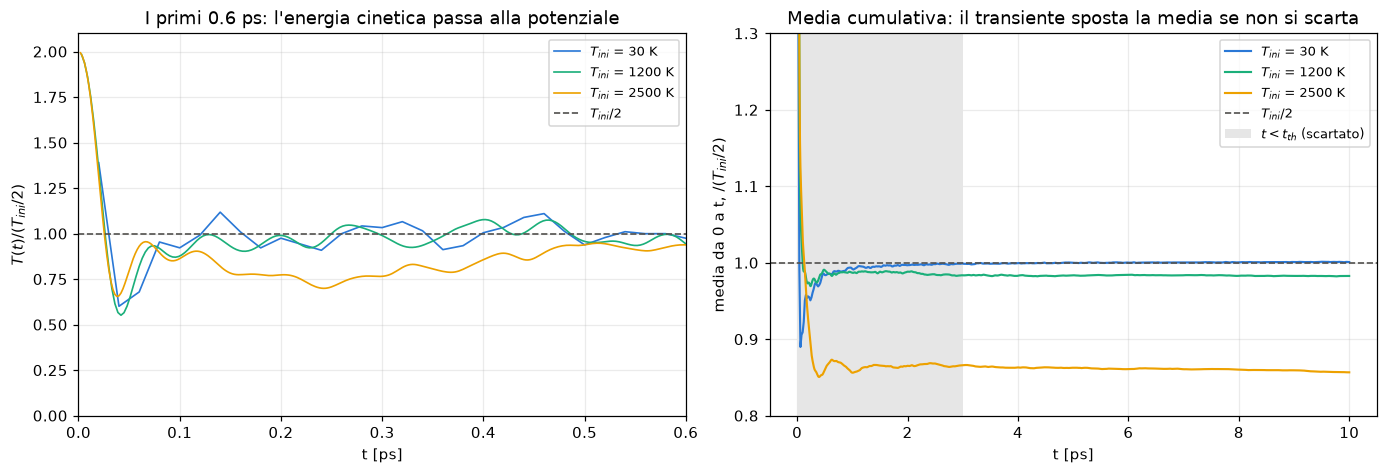

,primo passaggio sotto T_ini/2 [fs],⟨T⟩/(T_ini/2) dopo t_th,δT/⟨T⟩ istantaneo
T_ini [K],,,
30,40,1.002,0.041
1200,27,0.982,0.039
2500,26,0.853,0.038


In [10]:
transiente = {t: prova(raccordo, pos_min, t, DT_OTT[t], int(round(10_000 / DT_OTT[t]))) for t in (30.0, 1200.0, 2500.0)}
colori_tr = {30.0: COLORI[30.0], 1200.0: COLORI[1200.0], 2500.0: COLORI[2500.0]}

fig, (ax_z, ax_m) = plt.subplots(1, 2, figsize=(12.5, 4.2), constrained_layout=True)
righe = []
for t, p in transiente.items():
    res = p["res"]
    rapporto = res["T"] / (t / 2)
    media_mobile = np.cumsum(res["T"]) / np.arange(1, len(res["T"]) + 1) / (t / 2)
    ax_z.plot(res["time_ps"], rapporto, color=colori_tr[t], lw=1.1, label=f"$T_{{ini}}$ = {t:g} K")
    ax_m.plot(res["time_ps"], media_mobile, color=colori_tr[t], lw=1.4, label=f"$T_{{ini}}$ = {t:g} K")
    ith = int(round(T_TH_PS * 1000 / DT_OTT[t]))
    prod = res["T"][ith:]
    righe.append({"T_ini [K]": f"{t:g}",
                  "primo passaggio sotto T_ini/2 [fs]": f"{res['time_ps'][np.argmax(rapporto < 1)] * 1000:.0f}",
                  "⟨T⟩/(T_ini/2) dopo t_th": f"{prod.mean() / (t / 2):.3f}",
                  "δT/⟨T⟩ istantaneo": f"{prod.std() / prod.mean():.3f}"})
for ax in (ax_z, ax_m):
    ax.axhline(1.0, color=GRIGIO, ls="--", lw=1.1, label=r"$T_{ini}/2$")
ax_z.set(xlim=(0, 0.6), ylim=(0, 2.1), xlabel="t [ps]", ylabel=r"$T(t)/(T_{ini}/2)$",
         title="I primi 0.6 ps: l'energia cinetica passa alla potenziale")
ax_m.axvspan(0, T_TH_PS, color="0.9", lw=0, label="$t<t_{th}$ (scartato)")
ax_m.set(xlabel="t [ps]", ylabel=r"media da 0 a t, $/(T_{ini}/2)$", ylim=(0.8, 1.3),
         title="Media cumulativa: il transiente sposta la media se non si scarta")
ax_z.legend(fontsize=8.5)
ax_m.legend(fontsize=8.5)
plt.show()
display(pd.DataFrame(righe).set_index("T_ini [K]").style.set_caption(
    f"Transiente e fluttuazioni (10 ps dal minimo). Riferimenti per un solido armonico: "
    f"NVE √(1/3N) = {np.sqrt(1 / (3 * natoms)):.3f}, canonico √(2/3N) = {np.sqrt(2 / (3 * natoms)):.3f}"))

**Che cosa mostra.**

- **Transiente.** Partendo dal minimo, $T(t)$ scende dal valore iniziale
  ($2\times T_\text{ini}/2$) a circa metà in **25–40 fs**. È circa un quarto
  del periodo di vibrazione più breve del cluster (131 fs): il tempo che
  serve a un oscillatore per trasformare l'energia cinetica in potenziale.
  Poi $T$ oscilla, con oscillazioni che si smorzano in qualche decimo di ps,
  perché i modi hanno frequenze diverse e si sfasano.
- **Perché si scarta $t_{th}$.** Se si media da $t=0$ (grafico a destra), i
  primi istanti, con $T\approx T_\text{ini}$, spostano la media verso l'alto,
  e servono diversi ps perché il loro peso si diluisca. Scartando i primi
  $t_{th}=3$ ps si media solo $T(t)$ già all'equilibrio, che oscilla attorno a
  $T_f$.
- **Fluttuazioni.** Anche all'equilibrio la temperatura istantanea fluttua di
  circa il 4%. Non è un errore, ma l'effetto della taglia finita
  ($\propto1/\sqrt N$). In NVE, per un solido armonico, la teoria prevede
  $\delta T/\langle T\rangle=\sqrt{1/3N}=0.036$
  {cite}`lebowitz1967ensemble`, più piccolo del valore canonico
  $\sqrt{2/3N}$: le misure sono vicine al valore NVE. Per questo si usa la
  **media** su molti periodi, non il valore istantaneo.
- **Un dettaglio.** Nel caso armonico la regola $T_\text{ini}/2$ non richiede
  che l'energia si ridistribuisca tra i modi: ogni modo, da solo, divide in
  media a metà la propria energia tra cinetica e potenziale. L'equilibrio
  serve perché la media temporale sia quella giusta, cioè presa su tempi
  lunghi rispetto ai periodi e dopo il transiente.

### 4.3 Anarmonicità debole: il calcolo di $A$

Per un legame $V(x)=\tfrac12kx^2+c\,x^3+d\,x^4$, al primo ordine
nell'anarmonicità (derivazione nella [teoria](#sec:tini-mezzi), caso 3):

$$
\frac{\langle T\rangle}{T_\text{ini}/2}\simeq1-A\,k_B\langle T\rangle,
\qquad A=\frac{15c^2}{2k^3}-\frac{3d}{k^2}.
$$

- **Termine cubico** ($c$, asimmetria). Pesa sempre come $c^2>0$ e spinge
  $A>0$: il legame si allunga più facilmente di quanto si comprima,
  l'energia potenziale prende più della metà e $\langle T\rangle$ scende.
- **Termine quartico** ($d>0$, irrigidimento). Spinge $A<0$, e
  $\langle T\rangle$ sale.

Per LJ le derivate nel minimo danno $k$, $c$ e $d$, e quindi $A$. Il
risultato si confronta con il cluster, sia con LJ senza taglio ($r_c=8$ Å,
più run da 20 ps) sia con il $P_7$ (i run del punto 2).

k = 2.820 eV/Å², c = -3.326 eV/Å³, d = 4.950 eV/Å⁴
A = 15c²/(2k³) - 3d/k² = 3.699 - 1.867 = 1.832 1/eV  ->  A·ε = 0.632  (il cubico prevale: A > 0)


,⟨T⟩ [K],"⟨T⟩/(T_ini/2), i 2 run",E minimo finale − E cubo [eV],run riorganizzati,un legame: 1/(1 + A k_B⟨T⟩),A_eff / A (run regolari)
T_ini [K],,,,,,
100,50,0.996 / 0.996,+0.0 / +0.0,0,0.992,0.45
300,148,0.989 / 0.990,+0.0 / +0.0,0,0.977,0.46
500,245,0.982 / 0.981,+0.0 / +0.0,0,0.963,0.48
1000,480,0.961 / 0.957,+0.0 / +0.1,0,0.930,0.56
1500,705,0.942 / 0.938,-0.3 / -0.2,0,0.900,0.57
2000,1017,1.018 / 1.016,-9.3 / -7.8,2,0.862,—
2500,1239,0.987 / 0.995,-10.1 / -10.8,2,0.836,—


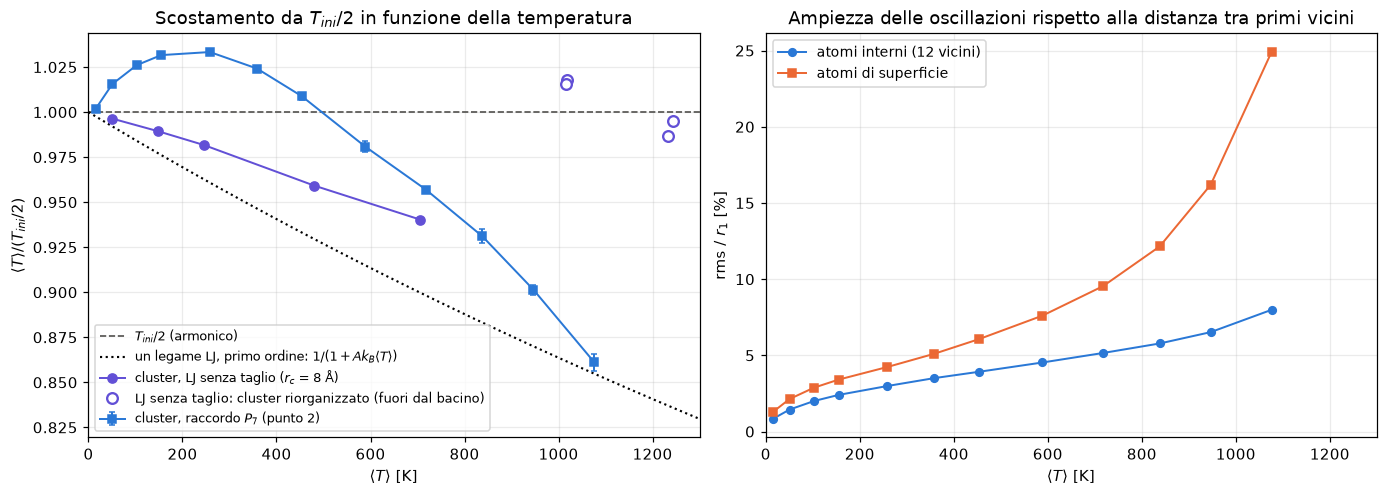

In [11]:
# LJ nel minimo r_m = 2^(1/6) σ: φ = ε[(r_m/r)^12 - 2 (r_m/r)^6]
r_m = 2 ** (1 / 6) * SIGMA
k_lj = EPSILON * (156 - 84) / r_m**2
c_lj = EPSILON * (-2184 + 672) / r_m**3 / 6
d_lj = EPSILON * (32760 - 6048) / r_m**4 / 24
A_lj = 15 * c_lj**2 / (2 * k_lj**3) - 3 * d_lj / k_lj**2  # 1/eV
print(f"k = {k_lj:.3f} eV/Å², c = {c_lj:.3f} eV/Å³, d = {d_lj:.3f} eV/Å⁴")
print(f"A = 15c²/(2k³) - 3d/k² = {15 * c_lj**2 / (2 * k_lj**3):.3f} - {3 * d_lj / k_lj**2:.3f} "
      f"= {A_lj:.3f} 1/eV  ->  A·ε = {A_lj * EPSILON:.3f}  (il cubico prevale: A > 0)")

cubo_lj = steepest_descent(pos0, lj_lungo, c=C_STEEP, ftol=F_TOL)
minimo_lj, e_cubo_lj = cubo_lj["pos"], cubo_lj["energy"][-1]
T_LJ = [100.0, 300.0, 500.0, 1000.0, 1500.0, 2000.0, 2500.0]
SOGLIA_RIORG = 3.0  # eV: minimo finale più profondo del cubo di oltre 3 eV (scalda di oltre 45 K)
lj_runs = []
for t in T_LJ:
    for s in SEMI[:2]:
        p = prova(lj_lungo, minimo_lj, t, 2, 10_000, seed=s)
        q = steepest_descent(p["res"]["pos"], lj_lungo, c=C_STEEP, ftol=F_TOL, max_iter=20_000)
        lj_runs.append({"T_ini": t, "T_mean": p["T_mean"], "dE_quench": q["energy"][-1] - e_cubo_lj})
lj = pd.DataFrame(lj_runs)
lj["rapporto"] = lj["T_mean"] / (lj["T_ini"] / 2)
lj["riorganizzato"] = lj["dE_quench"] < -SOGLIA_RIORG
regolari = lj[~lj["riorganizzato"]].groupby("T_ini")[["T_mean", "rapporto"]].mean()
t_lj, r_lj = regolari["T_mean"].to_numpy(), regolari["rapporto"].to_numpy()
A_eff = (1 / r_lj - 1) / (KB_EV * t_lj)  # dal cluster: 1/rapporto - 1 = A_eff k_B <T>

riassunto_lj = lj.groupby("T_ini").agg(rapporti=("rapporto", lambda v: " / ".join(f"{x:.3f}" for x in v)),
                                       quench=("dE_quench", lambda v: " / ".join(f"{x:+.1f}" for x in v)),
                                       riorganizzati=("riorganizzato", "sum"))
t_lj_tutti = lj.groupby("T_ini")["T_mean"].mean()
display(pd.DataFrame(
    {"⟨T⟩ [K]": [f"{v:.0f}" for v in t_lj_tutti.to_numpy()],
     "⟨T⟩/(T_ini/2), i 2 run": riassunto_lj["rapporti"].to_numpy(),
     "E minimo finale − E cubo [eV]": riassunto_lj["quench"].to_numpy(),
     "run riorganizzati": riassunto_lj["riorganizzati"].astype(int).to_numpy(),
     "un legame: 1/(1 + A k_B⟨T⟩)": [f"{1 / (1 + A_lj * KB_EV * v):.3f}" for v in t_lj_tutti.to_numpy()],
     "A_eff / A (run regolari)": [f"{A_eff[list(regolari.index).index(t)] / A_lj:.2f}" if t in regolari.index else "—"
                                  for t in T_LJ]},
    index=pd.Index([f"{t:g}" for t in T_LJ], name="T_ini [K]"),
).style.set_caption(f"Cluster con LJ senza taglio (r_c = 8 Å, 20 ps, 2 semi); «riorganizzato»: il minimo "
                    f"finale è più profondo del cubo di oltre {SOGLIA_RIORG:g} eV"))

fig, (ax_r, ax_a) = plt.subplots(1, 2, figsize=(12.5, 4.4), constrained_layout=True)
t_line = np.linspace(0, 1300, 200)
ax_r.axhline(1.0, color=GRIGIO, ls="--", lw=1.1, label=r"$T_{ini}/2$ (armonico)")
ax_r.plot(t_line, 1 / (1 + A_lj * KB_EV * t_line), ":", color="black", lw=1.4,
          label=r"un legame LJ, primo ordine: $1/(1+Ak_B\langle T\rangle)$")
ax_r.plot(t_lj, r_lj, "o-", color="#6250d6", ms=6, lw=1.3, label="cluster, LJ senza taglio ($r_c$ = 8 Å)")
riorg = lj[lj["riorganizzato"]]
if len(riorg):
    ax_r.plot(riorg["T_mean"], riorg["rapporto"], "o", color="#6250d6", mfc="white", mew=1.5, ms=7,
              label="LJ senza taglio: cluster riorganizzato (fuori dal bacino)")
ax_r.errorbar(t_med, t_med / (np.array(T_P2) / 2), yerr=t_std / (np.array(T_P2) / 2), fmt="s-",
              color="#2a78d6", ms=5, lw=1.3, capsize=2, label="cluster, raccordo $P_7$ (punto 2)")
ax_r.set(xlabel=r"$\langle T\rangle$ [K]", ylabel=r"$\langle T\rangle/(T_{ini}/2)$", xlim=(0, 1300),
         title="Scostamento da $T_{ini}/2$ in funzione della temperatura")
ax_r.legend(fontsize=8.2, loc="lower left")
r1 = A_AG / np.sqrt(2)
rms_int = np.array([np.mean([p["rms_interni"] for p in punto2[t]["runs"]]) for t in T_P2])
rms_sup = np.array([np.mean([p["rms_superficie"] for p in punto2[t]["runs"]]) for t in T_P2])
ax_a.plot(t_med, rms_int / r1 * 100, "o-", color="#2a78d6", ms=5, lw=1.3, label="atomi interni (12 vicini)")
ax_a.plot(t_med, rms_sup / r1 * 100, "s-", color="#eb6834", ms=5, lw=1.3, label="atomi di superficie")
ax_a.set(xlabel=r"$\langle T\rangle$ [K]", ylabel=r"rms / $r_1$ [%]", xlim=(0, 1300),
         title="Ampiezza delle oscillazioni rispetto alla distanza tra primi vicini")
ax_a.legend(fontsize=9)
plt.show()

**Che cosa mostra.**

- **Per un singolo legame LJ** il conto dà $A\varepsilon=0.63$. Il termine
  cubico prevale sul quartico, quindi $A>0$: il legame LJ è asimmetrico, cioè
  si allunga più facilmente di quanto si comprima. Al primo ordine
  $\langle T\rangle/(T_\text{ini}/2)\simeq1-0.63\,k_B\langle T\rangle/\varepsilon$
  scende **linearmente** con la temperatura (linea puntinata).
- **Il cluster con LJ senza taglio** (viola) scende anch'esso in modo lineare,
  con circa **metà** della pendenza: $A_\text{eff}/A$ passa da $0.45$ a $0.57$
  tra 50 e 700 K. Il modello a un legame coglie segno e andamento, mentre
  l'ampiezza dipende dal fatto che ogni atomo è tenuto da molti legami in
  direzioni diverse.
- **A destra**, l'ampiezza delle oscillazioni degli atomi interni resta sotto
  il 10% di $r_1$ anche a 1000 K e cresce dolcemente, come in un solido. Quella
  degli atomi di superficie cresce molto più in fretta: 8% a 600 K, 25% a
  1080 K. L'anarmonicità parte dalla superficie.

### 4.4 Irrigidimento: il raccordo $P_7$

Con il $P_7$ (quadrati blu) il rapporto **sale sopra 1** tra 100 e 900 K, al
massimo $1.033$ a 500 K, mentre LJ senza taglio resta sempre sotto. Il
controllo del §3 dà lo stesso risultato a 500 K: $1.033$ con il $P_7$, $0.976$
con il taglio netto, $0.983$ con LJ senza taglio.

È l'effetto del termine «quartico» del caso 4.3, cioè di un irrigidimento
($A<0$). Tra 4.2 e 4.5 Å il $P_7$ deve portare a zero energia e tre derivate
in soli 0.3 Å, quindi è molto curvo: fino a 5.9 eV/Å², contro 0.16 eV/Å² di LJ
in $r_p$ (calcolo nel notebook
[Esercizi CMS 6](../laboratori/cms6/esercizi_cms6.ipynb)). Le coppie di
secondi vicini che oscillano in quella zona sentono una molla più rigida della
parabola, prendono meno energia potenziale, e $\langle T\rangle$ sale. È un
**effetto del modello**, non della fisica dell'Ag. Oltre circa 900 K
l'anarmonicità di LJ e la mobilità della superficie prevalgono, e il rapporto
scende sotto 1.

### 4.5 Atomi fuori dal bacino

Ad alta temperatura alcuni atomi **lasciano il loro sito** (colonna «atomi
fuori sito» del punto 2: 1 a 900 K, 39 a 2500 K). Da quel momento il sistema
non oscilla più attorno al minimo di partenza: visita altri minimi della PES.
L'ipotesi armonica cade del tutto, perché il potenziale non è più una parabola
attorno a un solo punto. Per capire dove è finito il sistema, si minimizza la
configurazione finale e se ne confronta l'energia con quella del cubo di
partenza (ultime colonne delle tabelle). Si vedono due casi opposti.

- **Minimi più alti (difetti).** Con il $P_7$ il minimo raggiunto è sopra il
  cubo: da $+0.2$ a $+0.4$ eV tra 900 e 1500 K, $+1.9$ eV a 2500 K. Gli atomi che lasciano il
  sito formano difetti di superficie (adatomi e vacanze), che costano energia
  potenziale. Quell'energia resta immagazzinata e non torna cinetica, quindi
  $\langle T\rangle$ scende **più** di quanto preveda la sola anarmonicità. È
  l'analogo, in piccolo, del calore latente di fusione.
- **Minimi più bassi (riorganizzazione).** Con LJ senza taglio, a 2000 e
  2500 K, il minimo raggiunto è **8–11 eV sotto** il cubo. Il cluster ha
  trovato una forma più stabile: il cubo con spigoli e vertici non è la forma
  di minima energia. L'energia liberata scalda il sistema di oltre 100 K, e
  il rapporto **risale** a circa 1 (cerchi vuoti nel grafico). Non è la regola
  che torna a valere: sono due effetti che si compensano per caso.

Fuori dal bacino, quindi, $\langle T\rangle/(T_\text{ini}/2)$ non ha più un
valore definito. Dipende da quali minimi il sistema visita, e può cambiare nel
tempo e da una traiettoria all'altra.

### In sintesi

| Caso | Condizione violata | Effetto | Nei dati |
|---|---|---|---|
| Partenza dal minimo, regime armonico, media all'equilibrio | nessuna | $\langle T\rangle=T_\text{ini}/2$ | $1.002$ a 30 K |
| Partenza fuori dal minimo | 1 | $+\Delta U/(3Nk_B)$, peso $\propto1/T_\text{ini}$ | $1.21$ a 30 K, $0.86$ a 2500 K (punto 1) |
| Media senza scartare il transiente | 3 | media spostata verso $T_\text{ini}$ | §4.2, grafico a destra |
| Anarmonicità debole di LJ | 2, al primo ordine | $\simeq1-A\,k_B\langle T\rangle$, $A>0$: lineare | LJ senza taglio: $0.98$ a 245 K, $0.94$ a 705 K |
| Irrigidimento del $P_7$ | 2, effetto del modello | sopra 1 | $1.033$ a 500 K |
| Atomi fuori dal bacino | 2, del tutto | imprevedibile: difetti (giù) o riorganizzazione (su) | $0.86$ e $+1.9$ eV ($P_7$); $\approx1$ e $-10$ eV (LJ) |

**In una frase.** $\langle T\rangle=T_\text{ini}/2$ è l'equipartizione tra
energia cinetica e potenziale di oscillatori armonici. Vale se si parte dal
minimo, se le oscillazioni restano piccole ($k_BT\ll\varepsilon$, ampiezza
molto minore della distanza tra primi vicini) e se si media all'equilibrio.
Nel cluster di Ag è esatta a bassa temperatura. Con la temperatura si
allontana in modo lineare per l'anarmonicità (sotto 1 per LJ, sopra 1 per il
raccordo $P_7$), e perde significato quando gli atomi, a partire dalla
superficie, lasciano il proprio sito.

## Riepilogo

In [12]:
display(pd.DataFrame(
    [("1", "Δt ottimale con P7 (30 / 300 / 1200 / 2500 K)", " / ".join(f"{DT_OTT[t]:g} fs" for t in T_P1)),
     ("1", "taglio netto: passi validi", "; ".join(f"{t:g} K: {testo_validi(scan['netto'][t])}" for t in T_P1)),
     ("1", "traiettorie (rms dopo t_th, 30 K → 2500 K)",
      f"centro {tab_traj['30 K, centro']['rms attorno alla posizione media [Å]']} → "
      f"{tab_traj['2500 K, centro']['rms attorno alla posizione media [Å]']} Å; vertice "
      f"{tab_traj['30 K, vertice']['rms attorno alla posizione media [Å]']} → "
      f"{tab_traj['2500 K, vertice']['rms attorno alla posizione media [Å]']} Å"),
     ("2", "steepest descent", f"{iStep} iterazioni, ΔE = {e_min - energia[0]:.2f} eV"),
     ("2", "⟨T⟩/(T_ini/2) dal minimo, 30 → 2500 K",
      " / ".join(f"{m / (t / 2):.2f}" for t, m in zip(T_P2, t_med))),
     ("2", "⟨T⟩/(T_ini/2) dal reticolo (punto 1), 30 / 300 / 1200 / 2500 K",
      " / ".join(f"{m / (t / 2):.2f}" for t, m in zip(T_P1, t_p1)))],
    columns=["punto", "cosa", "risultato"],
).set_index("punto").style.set_caption("Exercise 1, PART 1 + 2"))

,cosa,risultato
punto,,
1,Δt ottimale con P7 (30 / 300 / 1200 / 2500 K),20 fs / 8 fs / 3 fs / 2 fs
1,taglio netto: passi validi,30 K: 1–25 fs; 300 K: nessuno; 1200 K: nessuno; 2500 K: nessuno
1,"traiettorie (rms dopo t_th, 30 K → 2500 K)",centro 0.025 → 0.190 Å; vertice 0.075 → 1.115 Å
2,steepest descent,"598 iterazioni, ΔE = -0.22 eV"
2,"⟨T⟩/(T_ini/2) dal minimo, 30 → 2500 K",1.00 / 1.02 / 1.03 / 1.03 / 1.03 / 1.02 / 1.01 / 0.98 / 0.96 / 0.93 / 0.90 / 0.86
2,"⟨T⟩/(T_ini/2) dal reticolo (punto 1), 30 / 300 / 1200 / 2500 K",1.21 / 1.06 / 0.99 / 0.86
